# Hospital Bed Capacity & Occupancy Analysis: Pune Municipal Corporation (PMC)

**Author:** Favour  |  **Tools:** Python (pandas, seaborn, matplotlib)  |  **Dataset:** PMC Hospital Infrastructure (737 facilities)

## 1. Objective and Context

**Business question:** How is hospital bed capacity distributed across Pune, and where is there evidence of capacity strain that should guide resource allocation and staffing?

**Who this is for:** Hospital administrators and public-health planners deciding where to add beds, staff or services.

**Analytical plan**
1. Audit data quality (including checks on whether the occupancy inputs can be trusted)
2. Clean and standardise categories
3. Describe bed capacity, ownership and staffing
4. Estimate occupancy only where the data supports it, and test how sensitive it is to assumptions
5. Summarise findings, limitations and recommended next steps

## 2. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.max_columns", 30)

raw = pd.read_csv(r'C:\Users\USER\Downloads\PMC Hospital Infrastructure.csv')
raw.columns = raw.columns.str.strip()  # source headers contain stray spaces
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
raw.head(3)

Rows: 737 | Columns: 17


,City Name,Zone Name,Ward Name,Zone No.,Ward No.,Facility Name,Type (Hospital / Nursing Home / Lab),Class : (Public / Private),Pharmacy Available : Yes/No,Number of Beds in Emergency Wards,Number of Beds in facility type,Number of Doctors / Physicians,Number of Nurses,Number of Midwives Professional,Average Monthly Patient Footfall,Ambulance Service Available,Count of Ambulance
0,Pune,kasba - vishrambagwada WO,Ambil Odha,5.0,NaN,"Late Matoshri Ramabai Ambedkar Maternity Home,...",Hospital (Maternity Home),Public,Yes,0,10,2,4,1,4500,Yes,1
1,Pune,Aundh - Baner WO,Aundh,2.0,NaN,"Aundh Kuti Maternity Home, Aundh",Hospital (Maternity Home),Public,Yes,0,14,2,5,2,2500,Yes,1
2,Pune,Aundh - Baner WO,Bopodi,2.0,NaN,Late Draupadabai Murlidhar Khedekar Maternity ...,Hospital (Maternity Home),Public,Yes,0,16,2,4,9,1900,Yes,1


## 3. Data Audit (before any cleaning)

In [2]:
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(1),
    "unique": raw.nunique(),
})
audit

,dtype,missing,missing_%,unique
City Name,object,0,0.0,1
Zone Name,object,32,4.3,18
Ward Name,object,2,0.3,80
Zone No.,float64,45,6.1,5
Ward No.,float64,737,100.0,0
Facility Name,object,0,0.0,708
Type (Hospital / Nursing Home / Lab),object,0,0.0,43
Class : (Public / Private),object,0,0.0,2
Pharmacy Available : Yes/No,object,0,0.0,3
Number of Beds in Emergency Wards,int64,0,0.0,6


`Ward No.` is 100% empty and `City Name` has a single value (Pune), so neither carries information. `Zone Name` and `Zone No.` are each partly missing and mix two encodings (numbers and names), which we reconcile below.

### 3.1 Can the occupancy inputs be trusted?
Occupancy needs a reliable **patient volume** measure and a **bed count**. Before calculating anything, I check both.

In [3]:
ff = raw["Average Monthly Patient Footfall"]
top = ff.value_counts().head(5)
print("Most common footfall values:\n", top.to_string(), "\n")
print(f"Share of rows with footfall exactly 2,550: {(ff == 2550).mean():.1%}")

cls = raw["Class : (Public / Private)"].str.strip().str.title()
print("\nFootfall == 2,550 by ownership class:")
print(pd.crosstab(cls, ff == 2550, rownames=["Class"], colnames=["Footfall is 2,550"]))

Most common footfall values:
 2550    663
2500      8
1100      6
1200      5
1800      4 

Share of rows with footfall exactly 2,550: 90.0%

Footfall == 2,550 by ownership class:
Footfall is 2,550  False  True 
Class                          
Private                0    663
Public                74      0


### ⚠️ Key data-quality finding
**90% of facilities report exactly 2,550 patients a month, and that is true of every private facility (663 rows).** Real monthly footfall would not be identical across hundreds of hospitals of very different sizes. This is almost certainly a **placeholder or imputed value** (likely the mean or median filled in at source), not an observation.

Only the **74 public-sector facilities** carry genuine footfall figures. This shapes the rest of the analysis: occupancy-type metrics are only valid for those facilities, while bed capacity and staffing can be analysed for all of them.

In [4]:
beds = raw["Number of Beds in facility type"]
print(f"Facilities with 0 beds: {(beds == 0).sum()}  (these are dispensaries / OPD-only sites)")
print(f"Bed count: median={beds.median():.0f}, mean={beds.mean():.1f}, max={beds.max()}")
print(f"Duplicate facility names: {raw['Facility Name'].duplicated().sum()}  | fully duplicated rows: {raw.duplicated().sum()}")
print(f"Rows where emergency beds > total beds: {(raw['Number of Beds in Emergency Wards'] > beds).sum()}")

Facilities with 0 beds: 54  (these are dispensaries / OPD-only sites)
Bed count: median=7, mean=21.7, max=831
Duplicate facility names: 29  | fully duplicated rows: 0
Rows where emergency beds > total beds: 68


- Zero-bed facilities are outpatient-only, so an occupancy rate is undefined for them (the original notebook divided by zero here).
- Emergency beds exceeding total beds in some rows suggests the two fields are measured on different bases. I treat emergency beds as a separate field and do not add them to total capacity.

## 4. Data Cleaning

In [5]:
df = raw.copy()

# 4.1 Clear column names
df.columns = ["city", "zone_name", "ward", "zone_no", "ward_no", "facility", "type_raw", "class_raw",
              "pharmacy_raw", "emergency_beds", "beds", "doctors", "nurses", "midwives",
              "footfall", "ambulance_raw", "ambulances"]

# 4.2 Drop columns with no information
df = df.drop(columns=["ward_no", "city"])

# 4.3 Standardise Yes/No and ownership fields
yn = {"yes": "Yes", "no": "No", "n.a.": "No"}
df["pharmacy"] = df["pharmacy_raw"].str.strip().str.lower().map(yn)
df["has_ambulance"] = df["ambulance_raw"].str.strip().str.lower().map(yn)
df["ownership"] = df["class_raw"].str.strip().str.title()

# 4.4 Collapse 43 messy spellings of facility type into clear groups
def facility_group(t):
    t = t.strip().lower()
    if t.startswith("dispensary"):                       return "Dispensary / OPD"
    if t.replace(" ", "") == "mat+gen":                  return "Maternity + General"
    if t in {"genral", "general", "gen", "hospital (general)"}: return "General"
    if "maternity" in t:                                 return "Maternity"
    if t.startswith("opt") or "opth" in t:               return "Ophthalmology"
    if t.startswith("ortho"):                            return "Orthopaedic"
    if t in {"ent", "mat+ent"}:                          return "ENT"
    if t in {"pediatric"}:                               return "Paediatric"
    if t in {"aurvedic", "homeopathic"} or "ayurved" in t: return "Ayurvedic / Homeopathic"
    if "infectious" in t:                                return "Infectious Disease"
    return "Other Specialty"
df["facility_type"] = df["type_raw"].apply(facility_group)

# 4.5 Reconcile zone: numeric zone number, with names recovered where possible
zone_from_name = pd.to_numeric(df["zone_name"], errors="coerce")           # name column sometimes holds the number
name_to_zone = (df.dropna(subset=["zone_no"]).dropna(subset=["zone_name"])
                  .assign(k=lambda d: d["zone_name"].str.strip().str.lower())
                  .groupby("k")["zone_no"].agg(lambda s: s.mode().iloc[0]))   # name -> most common zone number
zone_from_lookup = df["zone_name"].str.strip().str.lower().map(name_to_zone)
df["zone"] = df["zone_no"].fillna(zone_from_name).fillna(zone_from_lookup)
df["zone"] = df["zone"].map(lambda z: f"Zone {int(z)}" if pd.notna(z) else "Unassigned")

# 4.6 Flags that make the data-quality problems explicit and reusable
df["footfall_is_placeholder"] = df["footfall"] == 2550
df["is_inpatient"] = df["beds"] > 0

df = df.drop(columns=["pharmacy_raw", "ambulance_raw", "class_raw", "type_raw"])
print(f"Cleaned shape: {df.shape}")
print(df["facility_type"].value_counts().to_string())

Cleaned shape: (737, 18)
Maternity + General        282
General                    168
Ophthalmology               68
Maternity                   60
Dispensary / OPD            54
Other Specialty             52
Orthopaedic                 21
Paediatric                  13
ENT                         11
Ayurvedic / Homeopathic      7
Infectious Disease           1


In [6]:
cleaning_log = pd.DataFrame({
    "Step": ["Dropped empty / constant columns", "Standardised Yes/No fields", "Consolidated facility types",
             "Reconciled zone fields", "Flagged placeholder footfall", "Flagged inpatient facilities"],
    "Detail": ["ward_no (100% empty), city (single value)", "YES/yes/N.A. mapped to Yes/No",
               f"{raw.iloc[:, 6].nunique()} raw labels mapped to {df['facility_type'].nunique()} groups",
               f"{(df['zone']=='Unassigned').sum()} rows remain unassigned",
               f"{int(df['footfall_is_placeholder'].sum())} rows flagged (value = 2,550)",
               f"{int((~df['is_inpatient']).sum())} zero-bed facilities flagged"],
})
cleaning_log

,Step,Detail
0,Dropped empty / constant columns,"ward_no (100% empty), city (single value)"
1,Standardised Yes/No fields,YES/yes/N.A. mapped to Yes/No
2,Consolidated facility types,43 raw labels mapped to 11 groups
3,Reconciled zone fields,38 rows remain unassigned
4,Flagged placeholder footfall,"663 rows flagged (value = 2,550)"
5,Flagged inpatient facilities,54 zero-bed facilities flagged


## 5. Exploratory Analysis: Capacity

### 5.1 What does the facility network look like?

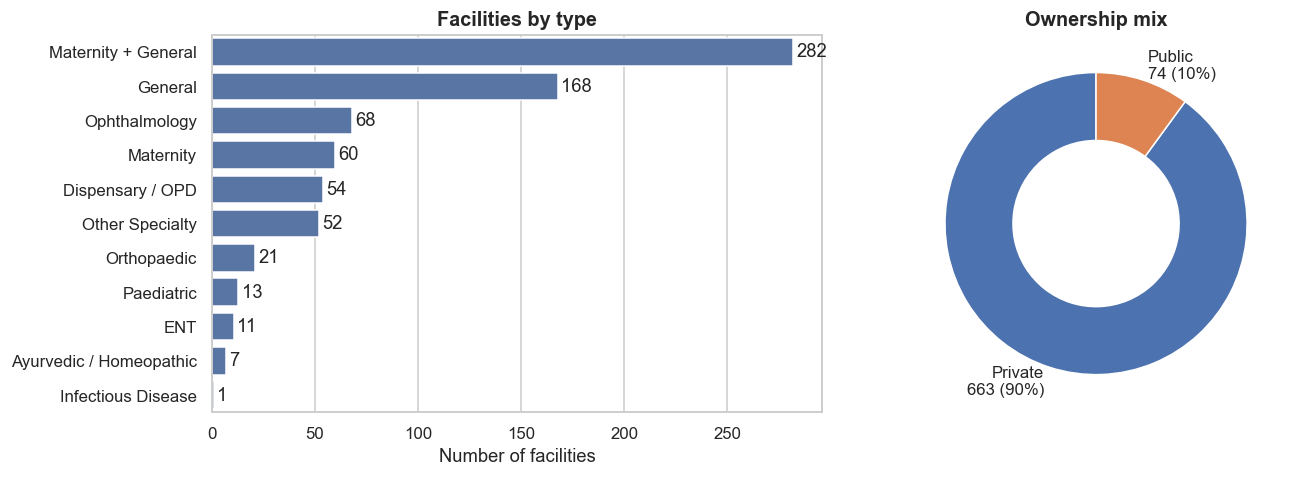

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

order = df["facility_type"].value_counts().index
sns.countplot(data=df, y="facility_type", order=order, color="#4C72B0", ax=axes[0])
axes[0].set_title("Facilities by type"); axes[0].set_xlabel("Number of facilities"); axes[0].set_ylabel("")
for c in axes[0].containers: axes[0].bar_label(c, padding=2)

own = df["ownership"].value_counts()
axes[1].pie(own, labels=[f"{k}\n{v} ({v/len(df):.0%})" for k, v in own.items()],
            colors=["#4C72B0", "#DD8452"], startangle=90, wedgeprops={"width": 0.45})
axes[1].set_title("Ownership mix")
plt.tight_layout(); plt.show()

The network is dominated by small private maternity/general facilities. Public facilities are about 10% of sites. The next view checks whether they are also about 10% of beds.

### 5.2 Where are the beds?

In [8]:
beds_by_own = df.groupby("ownership").agg(facilities=("facility", "count"),
                                           total_beds=("beds", "sum"),
                                           median_beds=("beds", "median"),
                                           max_beds=("beds", "max"))
beds_by_own["share_of_beds_%"] = (beds_by_own["total_beds"] / beds_by_own["total_beds"].sum() * 100).round(1)
beds_by_own

,facilities,total_beds,median_beds,max_beds,share_of_beds_%
ownership,,,,,
Private,663,14853,8.0,831,92.8
Public,74,1156,0.0,450,7.2


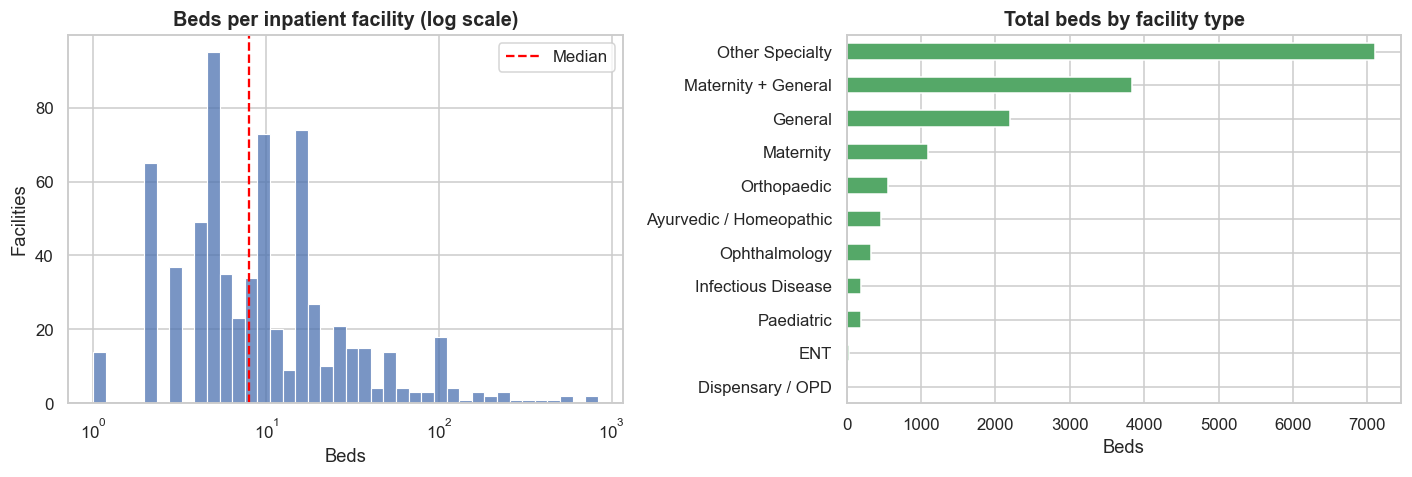

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Skewed distribution: show on a log scale so the typical facility is visible
sns.histplot(df.loc[df["is_inpatient"], "beds"], bins=40, log_scale=True, color="#4C72B0", ax=axes[0])
axes[0].set_title("Beds per inpatient facility (log scale)")
axes[0].set_xlabel("Beds"); axes[0].set_ylabel("Facilities")
axes[0].axvline(df.loc[df["is_inpatient"], "beds"].median(), color="red", ls="--", label="Median")
axes[0].legend()

tb = df.groupby("facility_type")["beds"].sum().sort_values()
tb.plot.barh(color="#55A868", ax=axes[1]); axes[1].set_title("Total beds by facility type")
axes[1].set_xlabel("Beds"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

In [10]:
inp = df[df["is_inpatient"]]
top10 = inp.nlargest(10, "beds")[["facility", "facility_type", "ownership", "beds"]]
top10["cum_share_of_all_beds_%"] = (top10["beds"].cumsum() / df["beds"].sum() * 100).round(1)
print(f"Top 10 facilities hold {top10['beds'].sum() / df['beds'].sum():.0%} of all {df['beds'].sum():,} beds")
top10.reset_index(drop=True)

Top 10 facilities hold 29% of all 16,009 beds


,facility,facility_type,ownership,beds,cum_share_of_all_beds_%
0,Bharti Hospital,Other Specialty,Private,831,5.2
1,Deenannath Mangeshkar Hospital,Other Specialty,Private,812,10.3
2,K.E.M. Hospital,Other Specialty,Private,568,13.8
3,Grant medical foundetion Ruby Holl Clinic,Other Specialty,Private,553,17.3
4,Kamla Nehru Hospital,General,Public,450,20.1
5,Sadhu Vaswani Mission Medical Complex (inlax ...,Other Specialty,Private,369,22.4
6,Jehangir Hospital,Other Specialty,Private,335,24.5
7,Poona Hospital & Reasarch Center,Other Specialty,Private,300,26.3
8,Nobel Hospital,Other Specialty,Private,250,27.9
9,sane guruji aarogya kendra,Maternity + General,Private,250,29.5


Bed capacity is highly concentrated. A handful of large hospitals hold a large share of all beds, while the typical facility has only a handful. Network-wide averages are therefore misleading, so I report medians alongside means.

### 5.3 Geographic distribution by zone

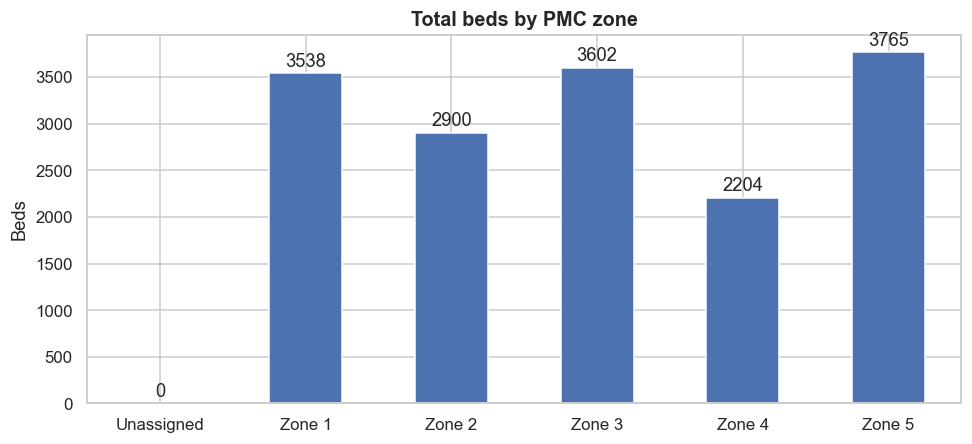

,facilities,total_beds,public_facilities,avg_beds_per_facility
zone,,,,
Unassigned,38,0,38,0.0
Zone 1,119,3538,4,29.7
Zone 2,170,2900,9,17.1
Zone 3,146,3602,3,24.7
Zone 4,111,2204,9,19.9
Zone 5,153,3765,11,24.6


In [11]:
zone_summary = df.groupby("zone").agg(facilities=("facility", "count"), total_beds=("beds", "sum"),
                                       public_facilities=("ownership", lambda s: (s == "Public").sum()))
zone_summary["avg_beds_per_facility"] = (zone_summary["total_beds"] / zone_summary["facilities"]).round(1)
zone_summary = zone_summary.sort_index()

fig, ax = plt.subplots(figsize=(9, 4.2))
zone_summary["total_beds"].plot.bar(color="#4C72B0", ax=ax)
ax.set_title("Total beds by PMC zone"); ax.set_xlabel(""); ax.set_ylabel("Beds"); plt.xticks(rotation=0)
for c in ax.containers: ax.bar_label(c, padding=2)
plt.tight_layout(); plt.show()
zone_summary

## 6. Exploratory Analysis: Staffing and Services

In [12]:
inp = df[df["is_inpatient"]].copy()
inp["beds_per_nurse"] = inp["beds"] / inp["nurses"].replace(0, np.nan)
inp["beds_per_doctor"] = inp["beds"] / inp["doctors"].replace(0, np.nan)

staff = inp.groupby("facility_type").agg(facilities=("facility", "count"), median_beds=("beds", "median"),
                                         median_beds_per_nurse=("beds_per_nurse", "median"),
                                         median_beds_per_doctor=("beds_per_doctor", "median")).round(1)
staff.sort_values("median_beds_per_nurse", ascending=False)

,facilities,median_beds,median_beds_per_nurse,median_beds_per_doctor
facility_type,,,,
Other Specialty,52,76.0,38.0,38.0
Infectious Disease,1,200.0,28.6,50.0
Ayurvedic / Homeopathic,7,15.0,7.5,7.5
Orthopaedic,21,14.0,7.0,7.0
Maternity + General,282,9.0,4.5,4.5
General,168,8.0,4.0,4.0
Paediatric,13,8.0,4.0,4.0
Maternity,60,10.0,3.0,4.5
ENT,11,2.0,1.0,1.0


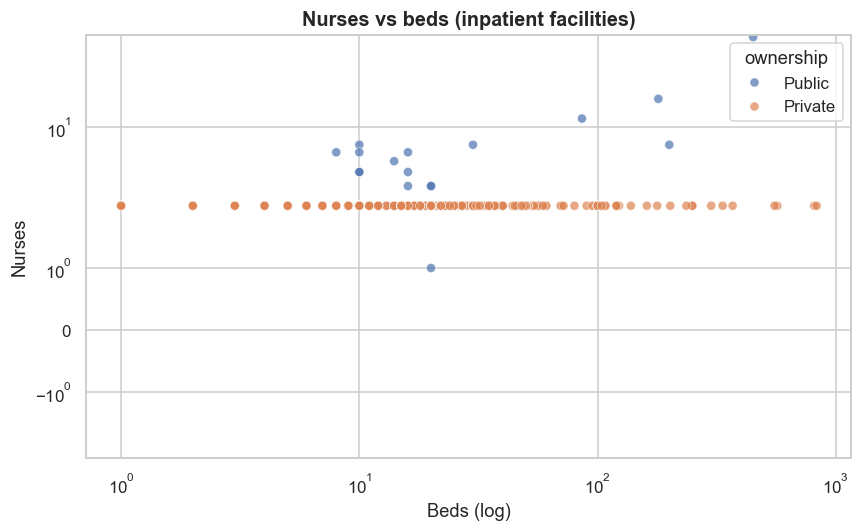

Correlation (Spearman) beds vs nurses: 0.12
Correlation (Spearman) beds vs doctors: 0.1


In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=inp, x="beds", y="nurses", hue="ownership", alpha=.7, ax=ax)
ax.set_xscale("log"); ax.set_yscale("symlog")
ax.set_title("Nurses vs beds (inpatient facilities)"); ax.set_xlabel("Beds (log)"); ax.set_ylabel("Nurses")
plt.tight_layout(); plt.show()

print("Correlation (Spearman) beds vs nurses:", round(inp[["beds", "nurses"]].corr(method="spearman").iloc[0, 1], 2))
print("Correlation (Spearman) beds vs doctors:", round(inp[["beds", "doctors"]].corr(method="spearman").iloc[0, 1], 2))

In [14]:
inp = inp.assign(bed_band=pd.cut(inp["beds"], [0, 10, 30, 100, 1000], labels=["1-10", "11-30", "31-100", "100+"]))
band = inp.groupby("bed_band", observed=True).agg(facilities=("facility", "count"),
                                                   median_nurses=("nurses", "median"),
                                                   median_beds_per_nurse=("beds_per_nurse", "median")).round(1)
band

,facilities,median_nurses,median_beds_per_nurse
bed_band,,,
1-10,425,2.0,2.5
11-30,171,2.0,7.5
31-100,58,2.0,24.8
100+,29,2.0,61.5


**Staffing reading.** Nurse and doctor counts barely change with facility size (many facilities report the same staffing figure). That is another sign some staffing fields may also be templated, so beds-per-nurse ratios should be treated as indicative, not exact. Even so, the largest facilities show visibly higher beds-per-nurse ratios, which is the kind of strain signal worth validating with real rosters.

In [15]:
svc = pd.crosstab(df["ownership"], [df["pharmacy"]], normalize="index").mul(100).round(1)
amb = pd.crosstab(df["ownership"], [df["has_ambulance"]], normalize="index").mul(100).round(1)
pd.concat({"Pharmacy on site (%)": svc, "Ambulance service (%)": amb}, axis=1)

Pharmacy on site (%)        Ambulance service (%)      
pharmacy                    No    Yes                    No   Yes
ownership                                                        
Private                   91.0    9.0                  93.1   6.9
Public                     0.0  100.0                  70.3  29.7

## 7. Bed Occupancy: What Can and Cannot Be Concluded

### 7.1 Why the original calculation needs revising
The standard definition is:

> **Bed Occupancy Rate (BOR) = occupied bed-days ÷ available bed-days × 100**

The dataset has no bed-days. It has *monthly patient footfall*, which counts visits and includes outpatients. This approach (`footfall ÷ (beds × 30)`) treats every visit as a full day in a bed. That produced rates above 100% for most facilities. 

### 7.2 A defensible alternative: patient load per bed (public facilities only)
Without bed-days, the honest metric is **monthly patients per bed**: a relative *pressure index*, not a percentage occupancy. It is comparable across facilities and meaningful only where footfall is real (the 74 public sites). Restricting to inpatient public facilities leaves a small sample, so results are descriptive.

In [16]:
pub = df[(df["ownership"] == "Public") & df["is_inpatient"]].copy()
pub["patients_per_bed_month"] = pub["footfall"] / pub["beds"]
pub = pub.sort_values("patients_per_bed_month", ascending=False)
print(f"Public inpatient facilities with observed footfall: {len(pub)}")
print(f"Median patients per bed per month: {pub['patients_per_bed_month'].median():.0f}")
pub[["facility", "facility_type", "beds", "footfall", "patients_per_bed_month"]].round(0).reset_index(drop=True)

Public inpatient facilities with observed footfall: 20
Median patients per bed per month: 152


,facility,facility_type,beds,footfall,patients_per_bed_month
0,"Late Jayabai Sutar Maternity Home, Kothrud",Maternity,10,5000,500.0
1,"Late Matoshri Ramabai Ambedkar Maternity Home,...",Maternity,10,4500,450.0
2,"Late Sakharam Kundalik Kodre Maternity Home, M...",Maternity,8,3500,438.0
3,"Late Savitribai Phule Maternity Home, Guruwarpeth",Maternity,10,3500,350.0
4,"Late Minatai Thakare Maternity Home, Kondhwa",Maternity,10,2600,260.0
5,"Dr. Homi J. Bhabha Maternity Home, Health Camp",Maternity,16,4000,250.0
6,"Late Anna Saheb Magar Maternity Home, Hadapsar",Maternity,20,4500,225.0
7,"Chatrpati Shivray Disp, Yerwada, Nagpur Chawl",Maternity,10,2000,200.0
8,"Late Namedevrao Shivarkar Maternity Home, Wanorie",Maternity,10,1900,190.0
9,"Aundh Kuti Maternity Home, Aundh",Maternity,14,2500,179.0


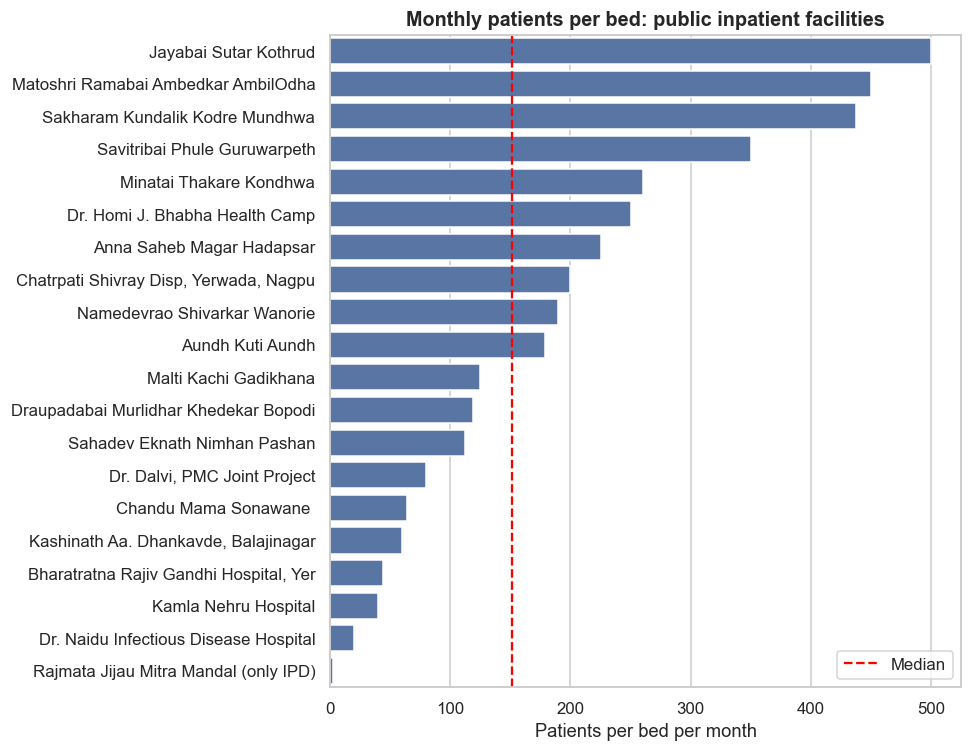

In [17]:
fig, ax = plt.subplots(figsize=(9, 7))
plot = pub.copy()
plot["label"] = plot["facility"].str.replace(r"Late |Maternity Home,? ?", "", regex=True).str[:38]
sns.barplot(data=plot, y="label", x="patients_per_bed_month", color="#4C72B0", ax=ax)
ax.axvline(plot["patients_per_bed_month"].median(), color="red", ls="--", label="Median")
ax.set_title("Monthly patients per bed: public inpatient facilities")
ax.set_xlabel("Patients per bed per month"); ax.set_ylabel(""); ax.legend()
plt.tight_layout(); plt.show()

**Reading this.** A high value means many patients are being served per bed, which is a sign of pressure. It does not prove beds are full. The facilities at the top of the ranking are candidates for a closer capacity review.

### 7.3 Sensitivity analysis: estimated occupancy under explicit assumptions
To get a true occupancy percentage you must assume (a) what share of footfall is **admitted** and (b) the **average length of stay (ALOS)**. Rather than hide these, lets show how the estimate changes across plausible values:

> Estimated BOR = (footfall × admission share × ALOS) ÷ (beds × 30) × 100

The assumption ranges below (2–10% of visits admitted, 2–5 day stays) are illustrative and should be replaced with PMC's actual admission data when available.

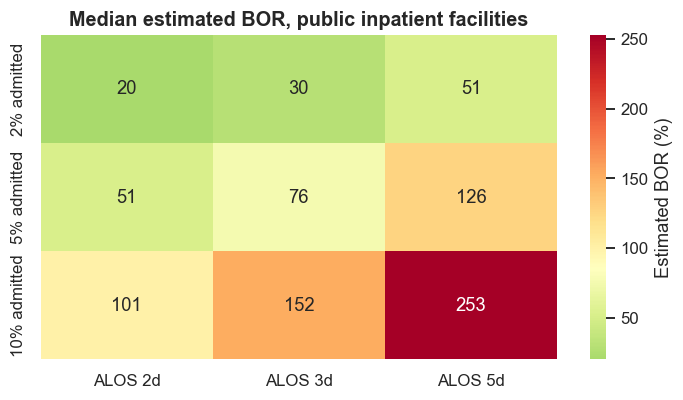

,ALOS 2d,ALOS 3d,ALOS 5d
Median estimated BOR (%),,,
2% admitted,20.0,30.0,51.0
5% admitted,51.0,76.0,126.0
10% admitted,101.0,152.0,253.0


In [18]:
def est_bor(frame, admit_share, alos):
    return (frame["footfall"] * admit_share * alos / (frame["beds"] * 30) * 100)

grid = pd.DataFrame(
    {f"ALOS {a}d": [est_bor(pub, s, a).median() for s in (0.02, 0.05, 0.10)] for a in (2, 3, 5)},
    index=[f"{int(s*100)}% admitted" for s in (0.02, 0.05, 0.10)],
).round(0)
grid.index.name = "Median estimated BOR (%)"

fig, ax = plt.subplots(figsize=(6.5, 3.8))
sns.heatmap(grid, annot=True, fmt=".0f", cmap="RdYlGn_r", center=85, cbar_kws={"label": "Estimated BOR (%)"}, ax=ax)
ax.set_title("Median estimated BOR, public inpatient facilities"); ax.set_ylabel("")
plt.tight_layout(); plt.show()
grid

The median estimate ranges from roughly 20% to over 250% depending on assumptions, which is exactly why a single occupancy figure from this dataset would be unsafe to present. Common benchmarks treat roughly 70–85% as an efficient range, with sustained levels above ~85% indicating strain.

## 8. Key Findings

1. **Occupancy cannot be computed reliably from this dataset as supplied.** 90% of footfall values are an identical placeholder (2,550), covering every private facility, and footfall counts visits rather than bed-days.
2. **Capacity is highly concentrated.** A few large hospitals hold a disproportionate share of beds, while the typical facility is small (median of 7 beds).
3. **Private facilities hold about 93% of all beds** (663 of 737 sites), while public facilities hold about 7%. Most public sites are zero-bed dispensaries (median public beds = 0), so the public network's role is mainly outpatient, with a few large inpatient hospitals such as Kamla Nehru.
4. **Patient load per bed varies widely across public maternity homes**, giving a ranked shortlist of facilities for capacity review.
5. **Staffing fields look partly templated**, so beds-per-nurse comparisons are indicative only. The largest facilities still show the highest ratios.
6. **Estimated occupancy is very sensitive to admission and length-of-stay assumptions** (section 7.3).

## 9. Limitations
- No bed-days, admissions or discharges, so true BOR, ALOS and turnover cannot be measured.
- Footfall is real only for public facilities (n=74, of which a small number have beds).
- Single snapshot with no date, so no seasonality or trend analysis is possible.
- Emergency-bed and staffing fields appear to be on inconsistent or templated bases.

## 10. Recommendations and Next Steps
1. **Collect bed-days and admissions** (or daily census) per facility to compute true BOR, ALOS and bed turnover.
2. **Replace placeholder footfall** with actual submissions, especially for private facilities.
3. **Add a date field** to enable monthly and seasonal occupancy trends.
4. **Prioritise a capacity review** of the public facilities with the highest patients-per-bed.
5. **Validate staffing data** against rosters before using it for workforce planning.